# 01 · Linear and logistic regression from scratch (NumPy), then check against sklearn & statsmodels

**Goal:** know what `.fit()` actually does, so you can answer "derive / explain logistic regression".
**Time:** ~2.5 hours.

| Model | Prediction | Loss | Gradient (w.r.t. weights) |
|---|---|---|---|
| Linear regression | ŷ = Xw + b | MSE = mean((ŷ − y)²) | (2/n)·Xᵀ(ŷ − y) |
| Logistic regression | p = σ(Xw + b), σ(z) = 1/(1+e⁻ᶻ) | Binary cross-entropy = −mean(y·log p + (1−y)·log(1−p)) | (1/n)·Xᵀ(p − y) |

Add L2 regularisation: loss + λ‖w‖² → gradient + 2λw.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, roc_auc_score, accuracy_score

## 1. Linear regression: closed form (normal equation) vs gradient descent

closed form  : [152.13  -0.48 -11.41  24.73]
grad descent : [152.13  -0.41 -11.33  24.91]
sklearn      : [152.13  -0.48 -11.41  24.73]


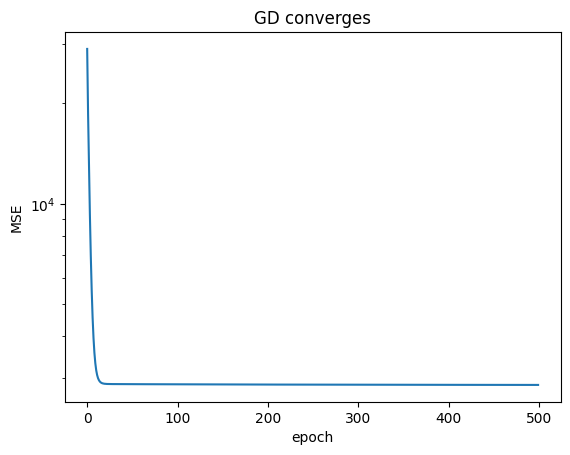

In [2]:
X, y = load_diabetes(return_X_y=True)
X = StandardScaler().fit_transform(X)
Xb = np.c_[np.ones(len(X)), X]                       # add bias column

w_closed = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)      # (XᵀX)⁻¹Xᵀy, solved stably

def gd_linear(Xb, y, lr=0.1, epochs=500):
    w = np.zeros(Xb.shape[1]); hist = []
    for _ in range(epochs):
        err = Xb @ w - y
        w -= lr * (2 / len(y)) * Xb.T @ err
        hist.append((err ** 2).mean())
    return w, hist

w_gd, hist = gd_linear(Xb, y)
sk = LinearRegression().fit(X, y)
print("closed form  :", w_closed[:4].round(2))
print("grad descent :", w_gd[:4].round(2))
print("sklearn      :", np.r_[sk.intercept_, sk.coef_][:4].round(2))
plt.plot(hist); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("GD converges"); plt.show()

Closed form costs O(d³) to invert; gradient descent scales to huge d and n (mini-batches). That's why
deep learning uses GD.

## 2. Logistic regression with gradient descent

In [3]:
Xc, yc = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=0)
sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def fit_logreg(X, y, lr=0.1, epochs=2000, l2=0.0):
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        p = sigmoid(X @ w + b)
        w -= lr * (X.T @ (p - y) / len(y) + 2 * l2 * w)
        b -= lr * (p - y).mean()
    return w, b

def bce(y, p, eps=1e-12):
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

w, b = fit_logreg(Xtr, ytr, l2=0.005)
p_mine = sigmoid(Xte @ w + b)
sk = LogisticRegression(C=1 / (2 * 0.005 * len(ytr)), max_iter=5000).fit(Xtr, ytr)
p_sk = sk.predict_proba(Xte)[:, 1]
print(f"mine   : acc {accuracy_score(yte, p_mine > 0.5):.3f}  AUC {roc_auc_score(yte, p_mine):.4f}  BCE {bce(yte, p_mine):.3f}")
print(f"sklearn: acc {accuracy_score(yte, p_sk > 0.5):.3f}  AUC {roc_auc_score(yte, p_sk):.4f}  BCE {bce(yte, p_sk):.3f}")

mine   : acc 0.951  AUC 0.9937  BCE 0.099
sklearn: acc 0.951  AUC 0.9939  BCE 0.099


**Why cross-entropy, not MSE, for classification?** With a sigmoid output, MSE gives a non-convex loss
and tiny gradients when the model is confidently wrong. Cross-entropy is convex for logistic regression and
punishes confident mistakes hard.

## 3. Interpreting coefficients: statsmodels gives p-values and confidence intervals
Logistic regression models **log-odds**: log(p/(1−p)) = b + w·x. So `exp(w)` = odds ratio per unit of x.

In [4]:
data = load_breast_cancer(as_frame=True)
cols = ["mean radius", "mean texture", "mean smoothness", "mean concave points"]
Xs = StandardScaler().fit_transform(data.frame[cols])
y_malig = 1 - data.target                          # 1 = malignant
res = sm.Logit(y_malig, sm.add_constant(Xs)).fit(disp=0)
table = np.exp(res.conf_int()); table.columns = ["OR 2.5%", "OR 97.5%"]
table["odds ratio"] = np.exp(res.params); table["p-value"] = res.pvalues
table.index = ["const"] + cols
table.round(3)

,OR 2.5%,OR 97.5%,odds ratio,p-value
const,0.307,0.721,0.471,0.001
mean radius,6.140,65.143,19.999,0.000
mean texture,2.819,7.725,4.666,0.000
mean smoothness,1.016,4.275,2.084,0.045
mean concave points,6.000,74.693,21.169,0.000


Read it as: "+1 standard deviation in mean concave points multiplies the odds of malignancy by ~X,
95% CI [a, b]". If the CI crosses 1, the effect is not significant at 5%.

## ✍️ Your turn
1. Add mini-batch gradient descent (batch size 32) to `fit_logreg`. Compare convergence speed.
2. Implement L1 regularisation (subgradient `l1 * sign(w)`). How many weights get close to 0?
3. Plot the decision boundary of your logistic regression on 2 features.

## 🎯 Interview check
- Derive the gradient of binary cross-entropy for logistic regression (say it in words).
- What does a coefficient of 0.7 mean in logistic regression?
- Why scale features before gradient descent?
- Linear regression assumptions (linearity, independence, homoscedasticity, normal residuals). Which matter for prediction vs inference?

In [5]:
# Your code here